# Delta updates to graph state

In [18]:
from typing import TypedDict, Optional, NotRequired
from langgraph.graph import StateGraph, START, END

## Define the Graph

In [19]:
class AppState(TypedDict):
    latest_step: Optional[str]
    logs: Optional[list['str']]

In [26]:
def step_one(state: AppState):
    
    return {
        'latest_step': 'step_one',
        'logs': ['Step 1 Completed']
    }

def step_two(state: AppState):

    return {
        'latest_step': 'step_two',
        'logs': ['Step 2 Completed']
    }

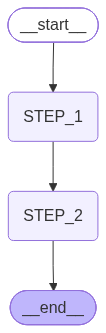

In [27]:
builder = StateGraph(AppState)

builder.add_node('STEP_1', step_one)
builder.add_node('STEP_2', step_two)

builder.add_edge(START, 'STEP_1')
builder.add_edge('STEP_1', 'STEP_2')
builder.add_edge('STEP_2', END)

graph = builder.compile()
graph

## Invoke the graph

In [28]:
initial_state = {}

print(graph.invoke(initial_state))

{'latest_step': 'step_two', 'logs': ['Step 2 Completed']}


Notes:

Notice the values of: `latest_step` and `logs` in the state

You can see that they both take on values updated from `step 2`

`step 2` has effectively overwritten original values set by `step 1`

Depending on your use case - this may / may not be desirable

May be desirable for `latest_step` but undesirable for `audit_logs`

Our general intution is for `audit_logs` to append / add onto existing data instead of overwriting.

How do we fix this ?

### Overwriting entire `logs` history at each step

In [32]:
class AppState(TypedDict):
    latest_step: Optional[str]
    logs: Optional[list['str']]

In [29]:
def step_one(state: AppState):

    logs = list(state.get('logs') or [])
    logs.append('Step 1 Completed')
    
    return {
        'latest_step': 'step_one',
        'logs': updated_logs
    }

def step_two(state: AppState):

    logs = list(state.get('logs') or [])
    logs = logs.append('Step 2 Completed')
    
    return {
        'latest_step': 'step_two',
        'logs': updated_logs
    }

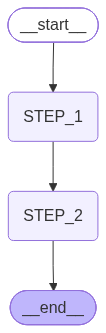

In [30]:
builder = StateGraph(AppState)

builder.add_node('STEP_1', step_one)
builder.add_node('STEP_2', step_two)

builder.add_edge(START, 'STEP_1')
builder.add_edge('STEP_1', 'STEP_2')
builder.add_edge('STEP_2', END)

graph = builder.compile()
graph

In [31]:
initial_state = {}

print(graph.invoke(initial_state))

NameError: name 'updated_logs' is not defined

### Annotating `logs` with the `add` operator

In [13]:
from typing import Annotated
from operator import add

In [14]:
class AppState(TypedDict):
    latest_step: Optional[str]
    logs: Annotated[Optional[list['str']], add] # this line was modified

In [15]:
def step_one(state: AppState):
    
    return {
        'latest_step': 'step_one',
        'logs': ['Step 1 Completed']
    }

def step_two(state: AppState):

    return {
        'latest_step': 'step_two',
        'logs': ['Step 2 Completed']
    }

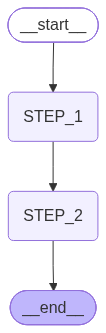

In [16]:
builder = StateGraph(AppState)

builder.add_node('STEP_1', step_one)
builder.add_node('STEP_2', step_two)

builder.add_edge(START, 'STEP_1')
builder.add_edge('STEP_1', 'STEP_2')
builder.add_edge('STEP_2', END)

graph = builder.compile()
graph

In [17]:
initial_state = {}

print(graph.invoke(initial_state))

{'latest_step': 'step_two', 'logs': ['Step 1 Completed', 'Step 2 Completed']}
